# ENSO dynamics

## Figure 8: ENSO nonlinearity

In [1]:
import json
from pathlib import Path
import cmip6_results
import matplotlib.pyplot as plt
import numpy as np
import plotstyle as ps
from scipy import stats

ps.apply()

In [2]:
DATA = Path("../data")
LIMITS = (-3.6, 3.6), (-3.6, 3.6)
RUNS = tuple(ps.ENSEMBLES["SamudrACE"])


def fit(pc1: np.ndarray, pc2: np.ndarray) -> tuple[np.ndarray, np.ndarray, float]:
    coefs = np.polyfit(pc1, pc2, 2)
    x = np.linspace(*np.percentile(pc1, [1, 99]), 100)
    return x, np.polyval(coefs, x), float(coefs[0])


def mean_fit(results: dict, members) -> tuple[np.ndarray, np.ndarray, float]:
    coefs = np.mean([np.polyfit(results[m]["djf_pcs"]["pc1"], results[m]["djf_pcs"]["pc2"], 2)
                     for m in members], axis=0)
    pc1 = np.concatenate([results[m]["djf_pcs"]["pc1"] for m in members])
    x = np.linspace(*np.percentile(pc1, [1, 99]), 100)
    return x, np.polyval(coefs, x), float(coefs[0])


def density(ax, x: np.ndarray, y: np.ndarray, colour: str) -> None:
    from matplotlib.colors import LinearSegmentedColormap
    from scipy.stats import gaussian_kde

    grid = np.linspace(-3.6, 3.6, 120)
    gx, gy = np.meshgrid(grid, grid)
    z = gaussian_kde(np.vstack([x, y]))(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
    cmap = LinearSegmentedColormap.from_list("d", ["white", colour])
    levels = np.linspace(z.max() * 0.08, z.max(), 6)
    ax.contourf(gx, gy, z, levels=levels, cmap=cmap, alpha=0.45, zorder=1, extend="max")


def cmip6_fits() -> list[tuple[np.ndarray, np.ndarray]]:
    out = []
    for entry in cmip6_results.alpha().values():
        x, y, _ = fit(np.array(entry["djf_pcs"]["pc1"]), np.array(entry["djf_pcs"]["pc2"]))
        out.append((x, y))
    return out


def guides(ax) -> None:
    x = np.linspace(-8, 8, 10)
    ax.plot(x, x, color=ps.GRID, lw=0.9, zorder=0)
    ax.plot(x, -x, color=ps.GRID, lw=0.9, zorder=0)
    ax.axhline(0, color=ps.GRID, lw=0.6, zorder=0)
    ax.axvline(0, color=ps.GRID, lw=0.6, zorder=0)
    ax.text(3.35, -3.35, "E", ha="center", va="center", color=ps.MUTED,
            fontsize=plt.rcParams["font.size"] + 1)
    ax.text(3.35, 3.35, "C", ha="center", va="center", color=ps.MUTED,
            fontsize=plt.rcParams["font.size"] + 1)
    ax.set_xlim(*LIMITS[0])
    ax.set_ylim(*LIMITS[1])
    ax.set_xlabel("PC1 (DJF)")
    ax.set_aspect("equal")


def scatter_panel(ax, alpha: dict) -> None:
    core = json.loads((DATA / "core_metrics.json").read_text())
    core.update(cmip6_results.core())
    cmip6 = cmip6_results.alpha()
    xs, ys = [], []
    for key, entry in cmip6.items():
        skew = core.get(key, {}).get("full_record", {}).get("EnsoSstSkew")
        if skew is not None and np.isfinite(skew):
            xs.append(skew)
            ys.append(entry["full_record"]["alpha"])
    xs, ys = np.array(xs), np.array(ys)
    ax.scatter(xs, ys, s=18, color=ps.COLORS["CMIP6"], alpha=0.9, lw=0, zorder=2,
               label=f"CMIP6 (ρ={stats.spearmanr(xs, ys)[0]:.2f})")
    coefs = np.polyfit(xs, ys, 1)
    xx = np.linspace(xs.min(), xs.max(), 10)
    ax.plot(xx, np.polyval(coefs, xx), color=ps.COLORS["CMIP6"], lw=1.0, zorder=1)
    for key, marker in (("SamudrACE", "o"), ("GFDL-CM4", "s"), ("ORAS5", "*")):
        members = ps.members(key)
        sx = np.mean([core[m]["full_record"]["EnsoSstSkew"] for m in members])
        sy = np.mean([alpha[m]["full_record"]["alpha"] for m in members])
        seg_x = np.concatenate([core[m]["segments"].get("EnsoSstSkew", []) for m in members])
        seg_y = np.concatenate([alpha[m].get("segments", {}).get("alpha", []) for m in members])
        if seg_x.size >= 3 and seg_y.size >= 3:
            (x0, x1), (y0, y1) = np.percentile(seg_x, [5, 95]), np.percentile(seg_y, [5, 95])
            ax.plot([x0, x1], [sy, sy], color=ps.COLORS[key], lw=1.6, alpha=0.5, zorder=3)
            ax.plot([sx, sx], [y0, y1], color=ps.COLORS[key], lw=1.6, alpha=0.5, zorder=3)
        if key == "ORAS5":
            ps.obs_whiskers(ax, sx, sy, ps.obs_bootstrap("core").get("EnsoSstSkew"),
                            ps.obs_bootstrap("alpha").get("alpha"))
        ax.scatter(sx, sy, s=110 if marker == "*" else 60, color=ps.COLORS[key], marker=marker,
                   edgecolor="white", lw=0.8, zorder=4,
                   label=ps.LABELS[key] if key != "ORAS5" else "ORAS5")
    ax.axhline(0, color=ps.GRID, lw=0.8, zorder=0)
    ax.axvline(0, color=ps.GRID, lw=0.8, zorder=0)
    ax.set_xlabel("Niño-3.4 SST anomaly skewness")
    ax.set_ylabel("α")
    ax.legend(loc="lower left", frameon=False)

In [3]:
results = json.loads((DATA / "alpha.json").read_text())

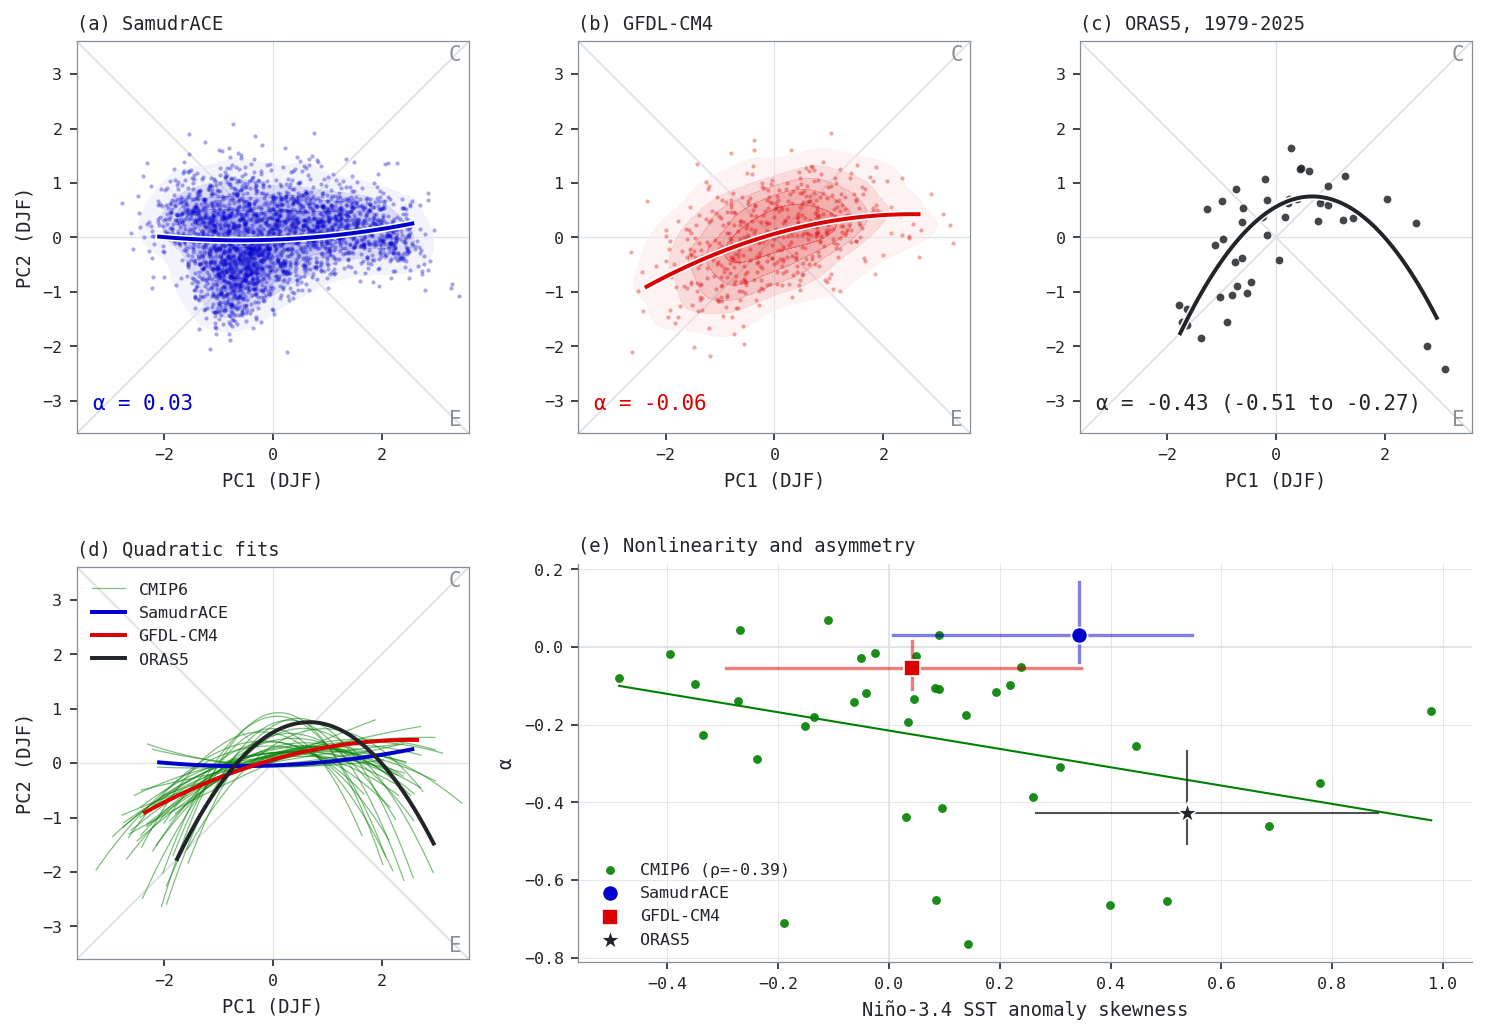

In [4]:
fig = plt.figure(figsize=(12.0, 8.0))
grid = fig.add_gridspec(2, 3, hspace=0.32, wspace=0.28)
marks = iter(ps.letters(5))

top = [fig.add_subplot(grid[0, i]) for i in range(3)]
for ax, key in zip(top, ("SamudrACE", "GFDL-CM4", "ORAS5")):
    colour = ps.COLORS[key]
    members = ps.members(key)
    pc1 = np.concatenate([results[m]["djf_pcs"]["pc1"] for m in members])
    pc2 = np.concatenate([results[m]["djf_pcs"]["pc2"] for m in members])
    if pc1.size > 100:
        density(ax, pc1, pc2, colour)
    ax.scatter(pc1, pc2, s=4 if pc1.size > 100 else 14, color=colour,
               alpha=0.35 if pc1.size > 100 else 0.85, lw=0, zorder=3)
    x, y, a = mean_fit(results, members)
    ax.plot(x, y, color="white", lw=3.4, zorder=4)
    ax.plot(x, y, color=colour, lw=1.9, zorder=5)
    guides(ax)
    text = f"α = {a:.2f}"
    if key == "ORAS5" and "alpha" in ps.obs_bootstrap("alpha"):
        lo, hi = ps.obs_bootstrap("alpha")["alpha"]
        text += f" ({lo:.2f} to {hi:.2f})"
    ax.text(0.04, 0.05, text, transform=ax.transAxes, ha="left", va="bottom",
            color=colour, fontsize=plt.rcParams["font.size"] + 1)
    name = ps.LABELS[key] if key != "ORAS5" else "ORAS5, 1979-2025"
    ps.panel_label(ax, name, next(marks))
top[0].set_ylabel("PC2 (DJF)")

ax = fig.add_subplot(grid[1, 0])
fits = cmip6_fits()
for i, (x, y) in enumerate(fits):
    ax.plot(x, y, color=ps.COLORS["CMIP6"], lw=0.6, alpha=0.5, zorder=2,
            label="CMIP6" if i == 0 else None)
for key in ("SamudrACE", "GFDL-CM4", "ORAS5"):
    x, y, _ = mean_fit(results, ps.members(key))
    ax.plot(x, y, color=ps.COLORS[key], lw=1.9, zorder=4,
            label=ps.LABELS[key] if key != "ORAS5" else "ORAS5")
guides(ax)
ax.set_ylabel("PC2 (DJF)")
ps.panel_label(ax, "Quadratic fits", next(marks))
ax.legend(loc="upper left", frameon=False, fontsize=plt.rcParams["font.size"] - 1)

ax = fig.add_subplot(grid[1, 1:])
scatter_panel(ax, results)
ps.panel_label(ax, "Nonlinearity and asymmetry", next(marks))
ps.tidy(ax, "both")

ps.save(fig, Path("../figures/alpha"))

## Figure 9: CLIVAR process metrics

In [5]:
import json
from pathlib import Path
import cmip6_results
import matplotlib.pyplot as plt
import numpy as np
import plotstyle as ps

ps.apply()

In [6]:
DATA = Path("../data")

PANELS = [
    ("EnsoFbSstTaux", "Bjerknes feedback", "10⁻³ N m⁻² °C⁻¹", 1e3),
    ("EnsoFbSstThf", "Heat flux damping", "W m⁻² °C⁻¹", 1.0),
    ("EnsodSstOce", "SST change by the ocean", "°C", 1.0),
    ("EnsoFbSshSst", "Thermocline feedback", "°C m⁻¹", 1.0),
    ("EnsoFbTauxSsh", "SSH response to wind", "m (N m⁻²)⁻¹", 1.0),
]


RUNS = tuple(ps.ENSEMBLES["SamudrACE"])

In [7]:
results = json.loads((DATA / "feedbacks.json").read_text())
results.update(cmip6_results.feedbacks())
ref = results["ORAS5"]["values"]
boot = ps.obs_bootstrap("feedbacks")
cmip6 = [k for k in results if k.startswith("CMIP6_")]

def ratio(keys, m):
    return np.mean([results[k]["values"][m] for k in keys]) / ref[m]

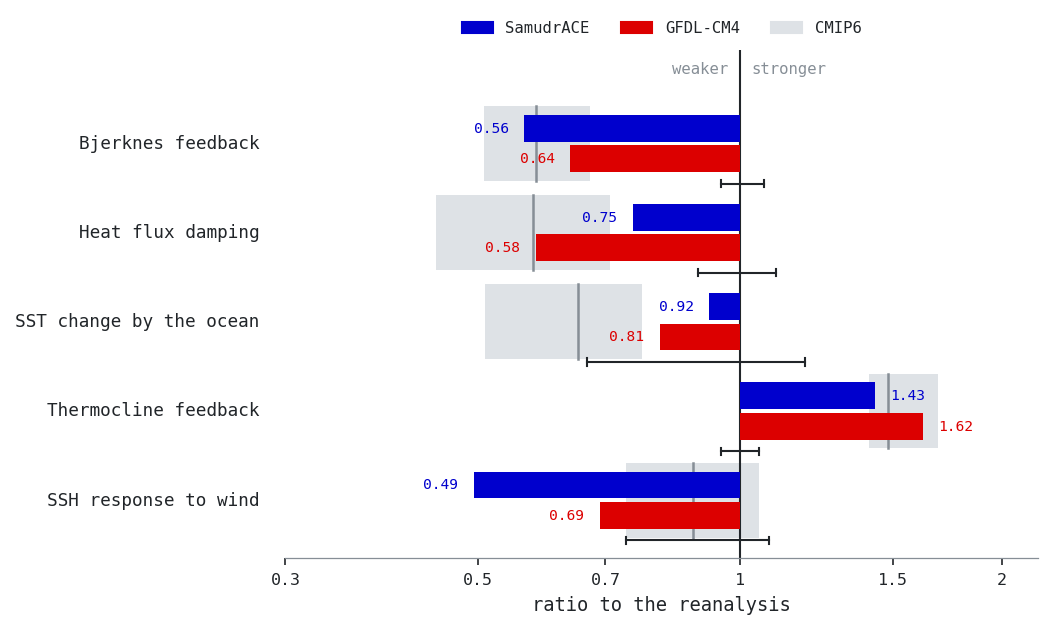

In [8]:
small = plt.rcParams["font.size"]
fig, ax = plt.subplots(figsize=(7.6, 4.4))
bars = (("SamudrACE", list(RUNS), 0.17), ("GFDL-CM4", ["GFDL-CM4"], -0.17))
for i, (m, label, unit, scale) in enumerate(PANELS):
    y = -i
    vals = np.array([ratio([k], m) for k in cmip6], float)
    q1, q2, q3 = np.nanpercentile(vals, [25, 50, 75])
    ax.add_patch(plt.Rectangle((q1, y - 0.42), q3 - q1, 0.84, fc=ps.GRID, ec="none",
                               zorder=0))
    ax.plot([q2, q2], [y - 0.42, y + 0.42], color=ps.MUTED, lw=1.2, zorder=1)
    for key, keys, dy in bars:
        v = ratio(keys, m)
        ax.barh(y + dy, v - 1, left=1, height=0.3, color=ps.COLORS[key], zorder=3)
        ax.text(v * (1.04 if v > 1 else 0.96), y + dy, f"{v:.2f}",
                ha="left" if v > 1 else "right", va="center", fontsize=small - 2,
                color=ps.COLORS[key])
    if m in boot:
        lo, hi = sorted(np.asarray(boot[m]) / ref[m])
        ax.plot([lo, hi], [y - 0.45] * 2, color=ps.INK, lw=1.0, zorder=3)
        ax.plot([lo, lo], [y - 0.49, y - 0.41], color=ps.INK, lw=1.0, zorder=3)
        ax.plot([hi, hi], [y - 0.49, y - 0.41], color=ps.INK, lw=1.0, zorder=3)
    ax.text(0.28, y, label, ha="right", va="center", fontsize=small - 0.5)
ax.axvline(1, color=ps.INK, lw=1.0, zorder=2)
ax.text(0.97, 0.75, "weaker", ha="right", va="bottom", color=ps.MUTED, fontsize=small - 1.5)
ax.text(1.03, 0.75, "stronger", ha="left", va="bottom", color=ps.MUTED, fontsize=small - 1.5)
ax.set_xscale("log")
ax.set_xlim(0.3, 2.2)
ax.set_xticks([0.3, 0.5, 0.7, 1, 1.5, 2])
ax.set_xticklabels(["0.3", "0.5", "0.7", "1", "1.5", "2"])
ax.minorticks_off()
ax.set_xlabel("ratio to the reanalysis")
ax.set_ylim(-len(PANELS) + 0.35, 1.05)
ax.set_yticks([])
ax.spines[["left", "right", "top"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=ps.COLORS["SamudrACE"], label="SamudrACE"),
           plt.Rectangle((0, 0), 1, 1, color=ps.COLORS["GFDL-CM4"], label="GFDL-CM4"),
           plt.Rectangle((0, 0), 1, 1, color=ps.GRID,
                         label="CMIP6")]
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3,
          frameon=False, fontsize=small - 1.5)
fig.subplots_adjust(left=0.31, right=0.97, top=0.9, bottom=0.13)
ps.save(fig, Path("../figures/feedbacks"))

## Figure 10: recharge oscillator

In [9]:
import json
from pathlib import Path
import cmip6_results
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import plotstyle as ps

ps.apply()

In [10]:
DATA = Path("../data")
BANDS = [
    ("2-3 yr", "var_frac_2_3yr"),
    ("3-4 yr", "var_frac_3_4yr"),
    ("4-6 yr", "var_frac_4_6yr"),
    ("6-8 yr", "var_frac_6_8yr"),
]


RUNS = tuple(ps.ENSEMBLES["SamudrACE"])


def isolines(ax, f, levels, fmt, xlim, ylim) -> None:
    gx, gy = np.meshgrid(np.linspace(*xlim, 200), np.linspace(*ylim, 200))
    cs = ax.contour(gx, gy, f(gx, gy), levels=levels, colors=ps.MUTED, linewidths=0.6,
                    linestyles=":", zorder=1)
    if fmt:
        ax.clabel(cs, fmt=fmt, fontsize=plt.rcParams["font.size"] - 3)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

In [11]:
res = json.loads((DATA / "xro_parameters.json").read_text())
res.update(cmip6_results.xro())
data = {k: dict(v) for k, v in res.items()}
n6 = len([k for k in data if k.startswith("CMIP6_")])

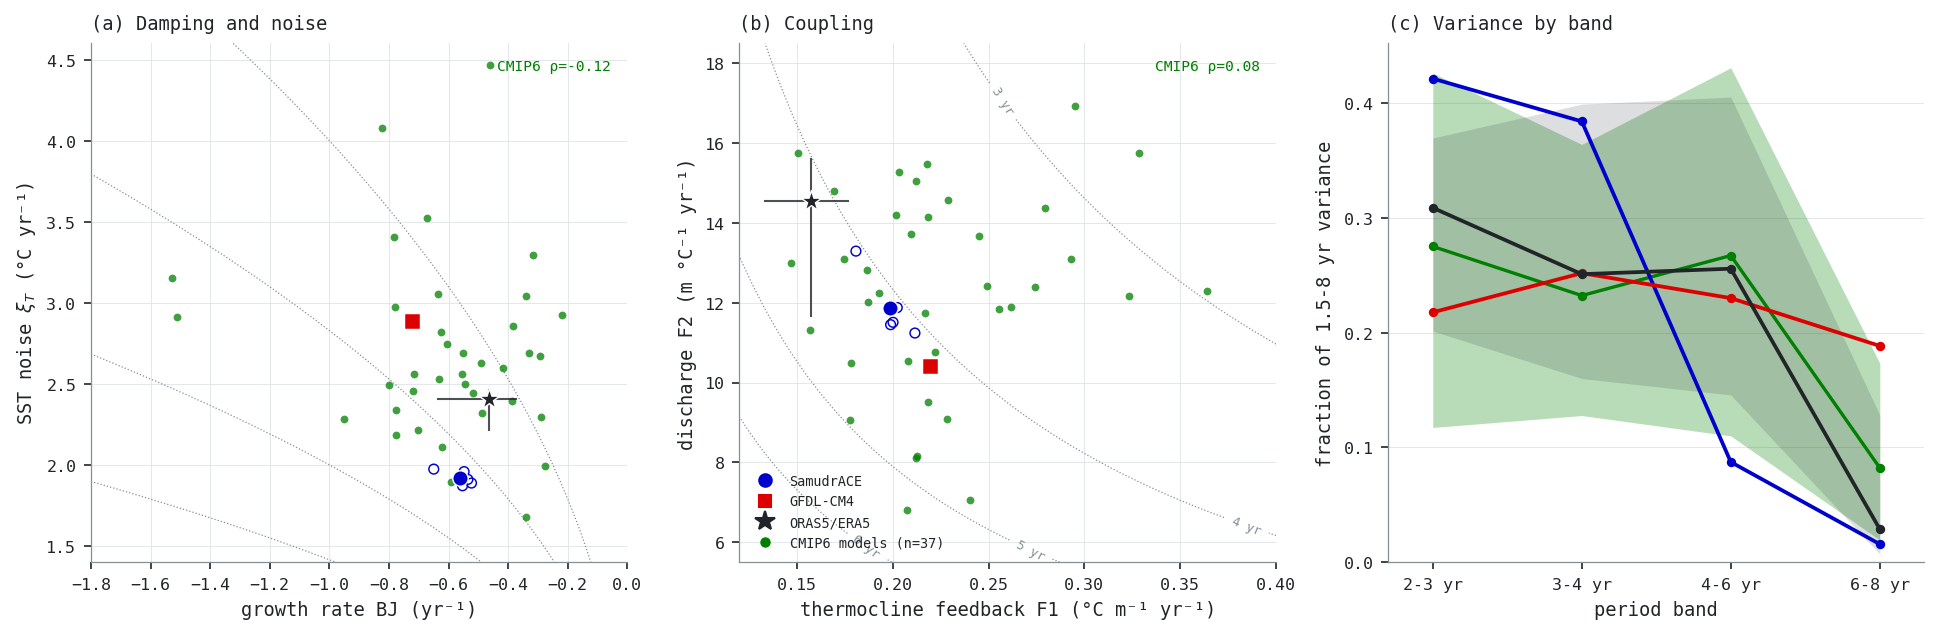

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.3))
marks = iter(ps.letters(3))

boot = ps.obs_bootstrap("xro")
ax = axes[0]
ps.pair_panel(ax, data, "BJ_ac", "xi_T", corr_at=(0.97, 0.97), obs_range=boot)
isolines(ax, lambda b, x: x**2 / (2 * np.abs(b)), [1, 2, 4, 8], None,
         (-1.8, 0.0), (1.4, 4.6))
ax.set_xlabel("growth rate BJ (yr⁻¹)")
ax.set_ylabel("SST noise $\\xi_T$ (°C yr⁻¹)")
ps.panel_label(ax, "Damping and noise", next(marks))

ax = axes[1]
ps.pair_panel(ax, data, "F1", "F2", corr_at=(0.97, 0.97), obs_range=boot)
isolines(ax, lambda a, b: 2 * np.pi / np.sqrt(np.maximum(a * b, 1e-6)), [3, 4, 5, 6, 8],
         "%g yr", (0.12, 0.40), (5.5, 18.5))
ax.set_xlabel("thermocline feedback F1 (°C m⁻¹ yr⁻¹)")
ax.set_ylabel("discharge F2 (m °C⁻¹ yr⁻¹)")
ps.panel_label(ax, "Coupling", next(marks))

for a_ in axes[:2]:
    ps.tidy(a_, "both")
axes[1].legend(handles=ps.pair_handles(n6), loc="lower left", frameon=False,
               fontsize=plt.rcParams["font.size"] - 2.5)

ax = axes[2]
xb = np.arange(len(BANDS))
rows = np.array([[res[k].get(name, np.nan) for _, name in BANDS]
                 for k in res if k.startswith("CMIP6_")], dtype=float)
lo, med, hi = np.nanpercentile(rows, [10, 50, 90], axis=0)
ax.fill_between(xb, lo, hi, color=ps.COLORS["CMIP6"], alpha=0.28, lw=0, zorder=1)
ax.plot(xb, med, color=ps.COLORS["CMIP6"], lw=1.6, marker="o", ms=3.5, zorder=2)
if all(name in boot for _, name in BANDS):
    ps.obs_band(ax, xb, np.array([boot[name] for _, name in BANDS]).T)
for key, members in (("SamudrACE", RUNS), ("GFDL-CM4", ("GFDL-CM4",)), ("ORAS5", ("ORAS5",))):
    means = [np.mean([res[m][name] for m in members]) for _, name in BANDS]
    ax.plot(xb, means, color=ps.COLORS[key], lw=1.8, marker="o", ms=3.5, zorder=4)
ax.set_xticks(xb)
ax.set_xticklabels([label for label, _ in BANDS])
ax.set_xlim(-0.3, len(BANDS) - 0.7)
ax.set_ylim(bottom=0)
ax.set_xlabel("period band")
ax.set_ylabel("fraction of 1.5-8 yr variance")
ps.panel_label(ax, "Variance by band", next(marks))
ps.tidy(ax)
fig.tight_layout()
ps.save(fig, Path("../figures/recharge_oscillator"))